### **Disclaimer buat mas-mas asdos**
Notebook ini di*run* melalui Colab sama vs code hihi

In [13]:
import os
from google.colab import drive

# 1. Mount Google Drive (Biarkan /content/drive karena ini standar mount point Colab)
drive.mount('/content/drive')

# 2. Clone atau Sinkronisasi Repo Github
repo_url = "https://github.com/username/Document-Image-Classification.git" # Jangan lupa ganti 'username'
repo_dir = "/content/Document-Image-Classification"

if not os.path.exists(repo_dir):
    print("Mengunduh repo baru (Clone)...")
    !git clone {repo_url}
else:
    print("Repo ditemukan, menyinkronkan pembaruan (Pull)...")
    %cd {repo_dir}
    !git pull origin main

# 3. MASUK KE REPO LOKAL (Menjawab idemu di Poin 1 & 2)
# Mulai dari titik ini, Colab bertingkah sama persis seperti VSCode-mu
%cd {repo_dir}

# 4. Buat folder 'data' di dalam repo
!mkdir -p data

# 5. Ekstrak data dari Drive ke folder 'data' lokal (Menjawab Poin 3 & 5)
zip_path = "/content/drive/MyDrive/Semester 5/SD4504_SML/Document-Image-Classification/data/document-image-classification-sd234504.zip"
csv_path = "/content/drive/MyDrive/Semester 5/SD4504_SML/Document-Image-Classification/data/train.csv"

print("Sedang mengekstrak ZIP ke folder 'data/'... (Mohon tunggu sebentar)")
!unzip -q "{zip_path}" -d data/
print("Menyalin train.csv...")
!cp "{csv_path}" data/

print("Setup Selesai! Berikut isi folder 'data' di dalam repo kamu sekarang:")
!ls -la data/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repo ditemukan, menyinkronkan pembaruan (Pull)...
/content/Document-Image-Classification
From https://github.com/gacoanphilia/Document-Image-Classification
 * branch            main       -> FETCH_HEAD
Already up to date.
/content/Document-Image-Classification
Sedang mengekstrak ZIP ke folder 'data/'... (Mohon tunggu sebentar)
replace data/sample_submission.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
Menyalin train.csv...
Setup Selesai! Berikut isi folder 'data' di dalam repo kamu sekarang:
total 2296
drwxr-xr-x 4 root root    4096 Oct 17 08:20 .
drwxr-xr-x 7 root root    4096 Oct 17 08:14 ..
-rw-r--r-- 1 root root  111926 Oct 15 01:25 sample_submission.csv
drwxr-xr-x 3 root root    4096 Oct 17 08:17 test
-rw-r--r-- 1 root root  255821 Oct 15 01:25 test.csv
drwxr-xr-x 3 root root    4096 Oct 17 08:19 train
-rw-r--r-- 1 root root 1958648 Oct 17 08:21 train.cs

In [14]:
import sys
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torch.optim as optim
from tqdm import tqdm
import torch.cuda.amp as amp

# Posisi kita sudah di root repo, jadi cukup merujuk ke "." (current directory)
sys.path.append(str(Path(".").resolve()))
from scripts.preprocess import DocumentDataset

# Hardware routing otomatis
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute Device: {device}")

# Path setup (Langsung tembak ke nama foldernya karena kita sudah di root)
DATA_DIR = Path("data").resolve()
TRAIN_CSV = DATA_DIR / "train.csv"

# Catatan: Pastikan struktur ZIP-mu.
# Jika saat diekstrak gambarnya langsung ada di dalam folder 'data/', ubah menjadi:
# IMG_ROOT = DATA_DIR
# Tapi jika di dalam ZIP ada folder 'train/' lagi, biarkan seperti di bawah:
IMG_ROOT = DATA_DIR / "train"

Compute Device: cuda


In [16]:
# Standard ImageNet normalization parameters
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Initialize the custom dataset
full_dataset = DocumentDataset(csv_file=TRAIN_CSV, data_dir=IMG_ROOT, transform=transform)
print(f"Total valid images loaded: {len(full_dataset)}")

# Split 80/20 for Train and Validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Initialize DataLoaders
# Dynamically check for a GPU to toggle pin_memory
use_pin_memory = torch.cuda.is_available()

# Initialize DataLoaders with the dynamic flag
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2, pin_memory=use_pin_memory)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2, pin_memory=use_pin_memory)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Total valid images loaded: 32002
Training batches: 1601
Validation batches: 401


Batch Image Tensor Shape: torch.Size([16, 3, 224, 224])
Batch Label Tensor Shape: torch.Size([16])


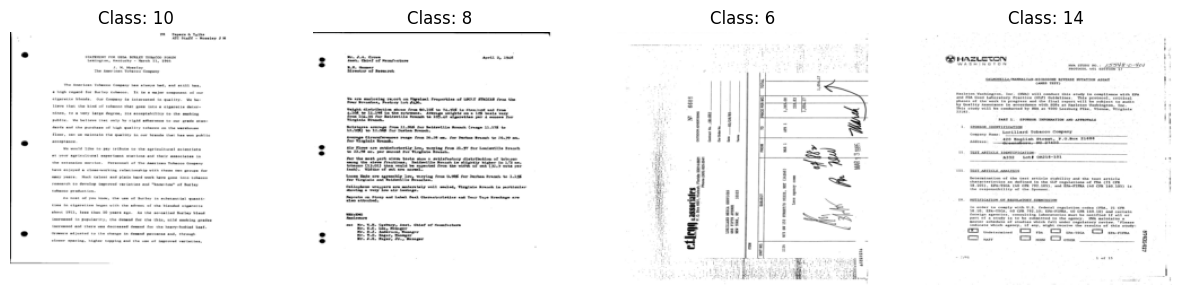

In [17]:
# Grab one batch
images, labels = next(iter(train_loader))

print(f"Batch Image Tensor Shape: {images.shape}") # Should be [16, 3, 224, 224]
print(f"Batch Label Tensor Shape: {labels.shape}") # Should be [16]

# Visualize the first 4 images in the batch (denormalize first for viewing)
def denormalize(tensor):
    tensor = tensor * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    return tensor.clamp(0, 1)

fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for i in range(4):
    img = denormalize(images[i]).permute(1, 2, 0)
    axes[i].imshow(img)
    axes[i].set_title(f"Class: {labels[i].item()}")
    axes[i].axis("off")
plt.show()

In [18]:
# Load pre-trained weights for faster convergence
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Freeze early layers to retain fundamental edge/texture detection
for param in model.features[:5].parameters():
    param.requires_grad = False

# Reconfigure the final classifier for 16 document classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 16)

model = model.to(device)
print(f"Model loaded and moved to: {device}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 97.5MB/s]


Model loaded and moved to: cuda


In [19]:
# Setup Model Directory (menyasar "root/models/")
MODEL_DIR = Path("..").resolve() / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Tentukan jumlah class (Sesuaikan dengan dataset-mu)
NUM_CLASSES = 16

label_map = {
    0: "advertisement",
    1: "budget",
    2: "email",
    3: "file_folder",
    4: "form",
    5: "handwritten",
    6: "invoice",
    7: "letter",
    8: "memo",
    9: "news_article",
    10: "presentation",
    11: "questionnaire",
    12: "resume",
    13: "scientific_publication",
    14: "scientific_report",
    15: "specification"
}

# Load pre-trained EfficientNet-B0
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# Modifikasi layer klasifikasi terakhir agar sesuai dengan jumlah class kita
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
model = model.to(device)

# Loss function dan Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# FIX WARNING: Menggunakan torch.amp.GradScaler sesuai standar PyTorch terbaru
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

print(f"Model siap! Direktori export: {MODEL_DIR}")

Model siap! Direktori export: /content/models


In [21]:
BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"
TOTAL_EPOCHS = 10

best_val_loss = float('inf')

print(f"[INFO] Memulai training dari awal selama {TOTAL_EPOCHS} Epochs dengan GPU...")

for epoch in range(TOTAL_EPOCHS):
    print(f"\nEpoch {epoch+1}/{TOTAL_EPOCHS}")

    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    train_bar = tqdm(train_loader, desc="Training", leave=False)
    for images, labels in train_bar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        # Mixed Precision Training (Mempercepat GPU T4)
        with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

        train_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    epoch_train_loss = train_loss / total_train
    epoch_train_acc = correct_train / total_train

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    val_bar = tqdm(val_loader, desc="Validation", leave=False)
    with torch.no_grad():
        for images, labels in val_bar:
            images, labels = images.to(device), labels.to(device)

            with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val

    print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")
    print(f"Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.4f}")

    # --- SAVE BEST MODEL ---
    # Hanya menyimpan bobot (state_dict) murni agar file lebih kecil dan siap untuk inferensi
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"--> Valid loss menurun! Best model diperbarui dan disimpan ke: {BEST_MODEL_PATH}")

print("\n[INFO] Training Selesai!")

[INFO] Memulai training dari awal selama 10 Epochs dengan GPU...

Epoch 1/10


Train Loss: 1.1274 | Train Acc: 0.6644
Val Loss:   0.8346 | Val Acc:   0.7474
--> Valid loss menurun! Best model diperbarui dan disimpan ke: /content/models/best_model.pth

Epoch 2/10


Train Loss: 0.7892 | Train Acc: 0.7626
Val Loss:   0.7564 | Val Acc:   0.7714
--> Valid loss menurun! Best model diperbarui dan disimpan ke: /content/models/best_model.pth

Epoch 3/10


Train Loss: 0.6660 | Train Acc: 0.7977
Val Loss:   0.6669 | Val Acc:   0.8050
--> Valid loss menurun! Best model diperbarui dan disimpan ke: /content/models/best_model.pth

Epoch 4/10


Train Loss: 0.5767 | Train Acc: 0.8249
Val Loss:   0.6355 | Val Acc:   0.8133
--> Valid loss menurun! Best model diperbarui dan disimpan ke: /content/models/best_model.pth

Epoch 5/10


...

Train Loss: 0.4390 | Train Acc: 0.8631
Val Loss:   0.6554 | Val Acc:   0.8177

Epoch 7/10


Train Loss: 0.3844 | Train Acc: 0.8764
Val Loss:   0.7547 | Val Acc:   0.8103

Epoch 8/10


Train Loss: 0.3323 | Train Acc: 0.8938
Val Loss:   0.7801 | Val Acc:   0.8011

Epoch 9/10


Train Loss: 0.2879 | Train Acc: 0.9077
Val Loss:   0.7213 | Val Acc:   0.8210

Epoch 10/10


Train Loss: 0.2477 | Train Acc: 0.9182
Val Loss:   0.7289 | Val Acc:   0.8241

[INFO] Training Selesai!
